In [1]:
%load_ext autoreload
%autoreload 2

# Device selection

In [2]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.result import QuasiDistribution
from qiskit_aer import AerSimulator

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)
simulator = AerSimulator.from_backend(backend)

# Tests with small circuit

In [3]:
from qiskit.converters import circuit_to_dag
from qiskit import QuantumCircuit
from sympy import fwht, ifwht
from copy import deepcopy
import numpy as np

def empty_copy_circ(circ: QuantumCircuit):
    new_circ=deepcopy(circ)
    new_circ.data=[]
    return new_circ

def copy_node(new_qc, node):
    '''Applies the node to the circuit.'''
    # Copy the node.
    if node.name=="x":
        new_qc.x(node.qargs[0])
    elif node.name=="y":
        new_qc.y(node.qargs[0])
    elif node.name=="z":
        new_qc.z(node.qargs[0])
    elif node.name=="h":
        new_qc.h(node.qargs[0])
    elif node.name=="s":
        new_qc.s(node.qargs[0])
    elif node.name=="sdg":
        new_qc.sdg(node.qargs[0])
    elif node.name=="t":
        new_qc.t(node.qargs[0])
    elif node.name=="tdg":
        new_qc.tdg(node.qargs[0])
    elif node.name=="cx":
        new_qc.cx(node.qargs[0], node.qargs[1])
    elif node.name=="cz":
        new_qc.cz(node.qargs[0], node.qargs[1])
    elif node.name=="cs":
        new_qc.cs(node.qargs[0], node.qargs[1])
    elif node.name=="csdg":
        new_qc.csdg(node.qargs[0], node.qargs[1])
    elif node.name=="cp":
        new_qc.cp(node.op.params[0], node.qargs[0], node.qargs[1])
    elif node.name=="swap":
        new_qc.swap(node.qargs[0], node.qargs[1])
    elif node.name=="rx":
        new_qc.rx(node.op.params[0], node.qargs[0])
    elif node.name=="rz":
        new_qc.rz(node.op.params[0], node.qargs[0])
    elif node.name=="sx":
        new_qc.sx(node.qargs[0])
    elif node.name=="measure":
        # print(node.qargs[0]._index, node.op.params, type(node.cargs[0]))
        new_qc.measure(node.qargs[0], node.cargs)
    elif node.name=="id":
        new_qc.id(node.qargs[0])
    elif node.name=="reset":
        new_qc.reset(node.qargs[0])
    elif node.name=="if_else":
        # print(node.qargs)
        # print(node.cargs)
        # print(node.op.params)
        # assert False, "error"
        with new_qc.if_test((node.cargs[0], 1)):
            new_qc.z(node.qargs[0])
    elif node.name=="barrier":
        new_qc.barrier()   
        
    else:
        # We have overlooked a gate type.
        assert False, f"{node.name} gate wasn't matched in the DAG."

def replace_gates_h_sx_rx(circ: QuantumCircuit):
    '''Replaces h with y and sx with x.'''
    dag=circuit_to_dag(circ)
    new_qc=empty_copy_circ(circ)   

    op_nodes=dag.op_nodes()
    for node in op_nodes:
        # print(node.name)
        if node.name=="h":
            new_qc.y(node.qargs[0])
        elif node.name=="sx" or node.name=="rx":
            new_qc.x(node.qargs[0])
        else:
            copy_node(new_qc, node)
    return new_qc

def first_col_update_label(col_label, key):
    num_qubits=len(col_label)
    return bin(int(col_label, 2) ^ int(key, 2))[2:].zfill(num_qubits)

def convert_to_first_col(counts: dict, col_label: str):
    '''The label is the associated column of tilde A. Counts is the associated column values.
    We should convert these to the first column by the symmetry rule described in the paper.'''
    counts={first_col_update_label(col_label, key):value for (key, value) in counts.items()}
    return counts

def filter_counts(counts, num_keep):
    '''Returns a dict with only the largest num_keep elements.'''
    list_counts=sorted(counts.items(), key=lambda x: -x[1])
    filtered_counts=list_counts[:num_keep:]
    return {k:v for (k,v) in filtered_counts}

def fill_counts_range(counts1: dict, counts2: dict, num_keep, num_qubits):
    '''We embed the counts into a power of 2 number of basis states by padding with zeros.
    Some things to note: This is necessary to match the keys for both dict. Also,
    since FWHT solvers only see a vector, when they pad they can do it in an
    unphysical fashion (e.g., 111 is in the distribution so no padding should occur after the 111.)
    args: num_keep: should be a power of 2. Both list should have the same keys for the
    inverse Fourier transforms to generate correct results.'''
    counts1_keys=set(counts1.keys())
    counts2_keys=set(counts2.keys())
    new_counts1={}
    new_counts2={}
    exist_keys=list(counts1_keys.union(counts2_keys))
    exist_keys=[int(elem, 2) for elem in exist_keys]
    exist_keys=sorted(exist_keys)
    # print("max exist ", max(exist_keys))
    # print("min exist ", min(exist_keys))
    # print("size before ", len(exist_keys))
    max_key=exist_keys[-1]
    min_key=exist_keys[0]
    current_len=len(exist_keys)
    if num_keep>=max_key:
        max_key=num_keep
        all_keys=list(range(num_keep))
    else: #num_keep<max_key. we will pad between until the size is right
        if num_keep<current_len: #the current len exceeds what was kept.
            # go to the nearest larger power of 2.
            power=int(np.ceil(np.log2(current_len)))
            max_key=num_keep=2**power
        all_possible_between=iter(range(min_key, max_key))
        all_possible_before=iter(range(0, min_key))
        new_keys_between=[]
        new_keys_before=[]
        # we should pad with elements between the min and max keys before outside.
        while len(new_keys_between)<num_keep-current_len:
            try:
                next_elem=next(all_possible_between)
                while next_elem in exist_keys:
                    try:
                        next_elem=next(all_possible_between)
                    except StopIteration:
                        raise StopIteration
            except StopIteration:
                break
            new_keys_between.append(next_elem)
        while len(new_keys_between)+len(new_keys_before)+len(exist_keys)<num_keep:
            # pad with before elements
            next_elem=next(all_possible_before)
            new_keys_before.append(next_elem)

        all_keys=exist_keys+new_keys_between+new_keys_before
        
    all_keys=[bin(elem)[2::].zfill(num_qubits) for elem in all_keys]

    for k in all_keys:
        new_counts1[k]=counts1.get(k,0)
        new_counts2[k]=counts2.get(k,0)
    assert len(all_keys)==len(new_counts1)
    assert len(all_keys)==len(new_counts2)

    return sorted(list(all_keys), key=lambda x: int(x)), new_counts1, new_counts2

def filled_dict_to_vec(filled_samples_dict):
    if not float(np.log2(len(filled_samples_dict))).is_integer():
        raise ValueError("The number of keys in the samples dict must be a power of 2.")
    sorted_distribution = sorted(list(filled_samples_dict.items()), key=lambda x: int(x[0], 2))
    return np.array([el[1] for el in sorted_distribution])

def get_quasi_corrected(noisy_noise_est_vec, counts_vec):
    '''Solves the circulant structure system with FWHT.'''
    fft_calmat_col=np.array(fwht(noisy_noise_est_vec), dtype=float)
    fft_noisy_counts=np.array(fwht(counts_vec), dtype=float)
    # print(len(fft_calmat_col))
    # print(len(fft_noisy_counts))
    quasi_corrected_counts=ifwht(np.divide(fft_noisy_counts, fft_calmat_col, out=np.zeros(len(fft_noisy_counts)), where=(fft_calmat_col!=0)))
    return np.array(quasi_corrected_counts, dtype=float)[0:len(noisy_noise_est_vec)]

def dec_mitigation(payload_noisy_samples, calibration_noisy_samples, calibration_ideal_samples, num_keep=2**20):
    if len(calibration_ideal_samples) != 1:
        raise ValueError("Calibration samples must only contain samples from a single basis state.")
    if sum(payload_noisy_samples.values()) != sum(calibration_noisy_samples.values()) != sum(calibration_ideal_samples.values()):
        raise ValueError("All samples dicts must contain the same number of shots.")
    shots = sum(payload_noisy_samples.values())
    calibration_column_label = list(calibration_ideal_samples.keys())[0]
    nqubits = len(calibration_column_label)

    # Generate the distribution vectors with correct ordering and length
    payload_noisy_samples = convert_to_first_col(payload_noisy_samples, calibration_column_label)
    payload_noisy_samples = filter_counts(payload_noisy_samples, num_keep)
    calibration_noisy_samples = filter_counts(calibration_noisy_samples, num_keep)
    final_labels, filled_payload_noisy_samples, filled_calibration_noisy_samples,  = fill_counts_range(payload_noisy_samples, calibration_noisy_samples, min(2**nqubits, num_keep), nqubits)
    filled_payload_samples_vec = filled_dict_to_vec(filled_payload_noisy_samples)
    filled_calibration_samples_vec = filled_dict_to_vec(filled_calibration_noisy_samples)

    # Get the corrected payload distribution
    payload_quasi_corrected_dist_vec = get_quasi_corrected(filled_calibration_samples_vec, filled_payload_samples_vec)
    payload_quasi_dist_dict = {label:prob for label, prob in zip(final_labels, payload_quasi_corrected_dist_vec)}
    payload_quasi_dist = QuasiDistribution(payload_quasi_dist_dict)
    payload_dist_dict = payload_quasi_dist.nearest_probability_distribution().binary_probabilities(nqubits)

    return payload_dist_dict

In [4]:
from qiskit import QuantumCircuit, generate_preset_pass_manager

n = 10

qc = QuantumCircuit(n)
qc.h(0)
for i in range(n-1):
    qc.cx(i, i + 1)
qc.measure_all()

pm = generate_preset_pass_manager(backend=simulator, optimization_level=3)
tqc = pm.run(qc)

testc = replace_gates_h_sx_rx(tqc)

testc.draw(idle_wires=False)

global phase: 3π/4
           ┌─────────┐┌───┐ ┌───────┐                                          »
q_5 -> 123 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──────────────────────────────────────────»
           ├─────────┤├───┤ ├───────┤                                          »
q_4 -> 124 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──────────────────────────────────────────»
           ├─────────┤├───┤ ├───────┤                                          »
q_3 -> 125 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├────────────────────────────────────────■─»
           ├─────────┤├───┤ ├───────┤                       ┌───┐┌─────────┐ │ »
q_2 -> 126 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├─────────────────────■─┤ X ├┤ Rz(π/2) ├─■─»
           ├─────────┤├───┤ ├───────┤    ┌───┐┌─────────┐ │ └───┘└─────────┘   »
q_1 -> 127 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──■─┤ X ├┤ Rz(π/2) ├─■────────────────────»
           ├─────────┤├───┤ ├───────┤  │ └───┘└─────────┘                      »
q_6 -> 136 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──┼───────────────────────────────────────»
           ├─────────┤├───┤┌┴───────┴┐ │                                       »
q_0 -> 137 ┤ Rz(π/2) ├┤ X ├┤ Rz(π/2) ├─■───────────────────────────────────────»
           ├─────────┤├───┤└┬───────┬┘                                         »
q_9 -> 141 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──────────────────────────────────────────»
           ├─────────┤├───┤ ├───────┤                                          »
q_8 -> 142 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──────────────────────────────────────────»
           ├─────────┤├───┤ ├───────┤                                          »
q_7 -> 143 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──────────────────────────────────────────»
           └─────────┘└───┘ └───────┘                                          »
  meas: 10/════════════════════════════════════════════════════════════════════»
                                                                               »
«                                                 ┌───┐┌─────────┐        »
«q_5 -> 123 ────────────────────────────────────■─┤ X ├┤ Rz(π/2) ├─■──────»
«                              ┌───┐┌─────────┐ │ └───┘└─────────┘ │      »
«q_4 -> 124 ─────────────────■─┤ X ├┤ Rz(π/2) ├─■──────────────────┼──────»
«           ┌───┐┌─────────┐ │ └───┘└─────────┘                    │      »
«q_3 -> 125 ┤ X ├┤ Rz(π/2) ├─■─────────────────────────────────────┼──────»
«           └───┘└─────────┘                                       │      »
«q_2 -> 126 ───────────────────────────────────────────────────────┼──────»
«                                                                  │      »
«q_1 -> 127 ───────────────────────────────────────────────────────┼──────»
«                                                                  │ ┌───┐»
«q_6 -> 136 ───────────────────────────────────────────────────────■─┤ X ├»
«                                                                    └───┘»
«q_0 -> 137 ──────────────────────────────────────────────────────────────»
«                                                                         »
«q_9 -> 141 ──────────────────────────────────────────────────────────────»
«                                                                         »
«q_8 -> 142 ──────────────────────────────────────────────────────────────»
«                                                                         »
«q_7 -> 143 ──────────────────────────────────────────────────────────────»
«                                                                         »
«  meas: 10/══════════════════════════════════════════════════════════════»
«                                                                         »
«                                                                    »
«q_5 -> 123 ─────────────────────────────────────────────────────────»
«                                                                    »
«q_4 -> 124 ─────────────────────────────────────────────────────────»
«                                                                    »
«q_3 -> 125 ───

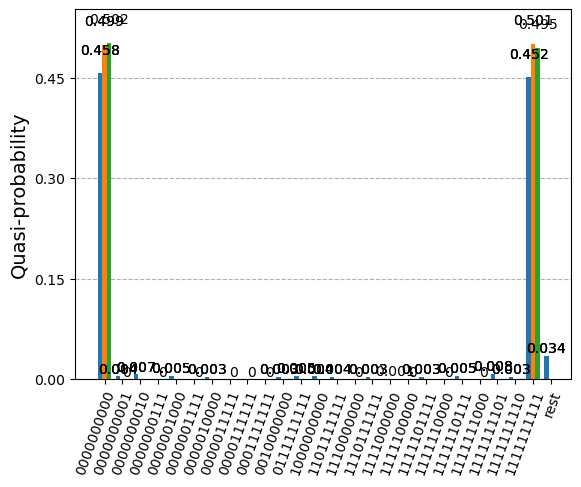

In [5]:
from qiskit.visualization import plot_histogram

ideal_simulator = AerSimulator(method="stabilizer")

noisy_samples_dicts = simulator.run(tqc, shots=100000).result().get_counts()
ideal_samples_dicts = ideal_simulator.run(tqc, shots=100000).result().get_counts()
test_noisy_samples_dicts = simulator.run(testc, shots=100000).result().get_counts()
test_ideal_samples_dicts = ideal_simulator.run(testc, shots=100000).result().get_counts()

corrected_samples_dicts = dec_mitigation(noisy_samples_dicts, test_noisy_samples_dicts, test_ideal_samples_dicts)

# plot_histogram([test_noisy_samples_dicts, test_ideal_samples_dicts], number_to_keep=15)
plot_histogram([noisy_samples_dicts, ideal_samples_dicts, corrected_samples_dicts], number_to_keep=15)

In [6]:
corrected_samples_dicts

{'1111111000': 2.879562551621421e-05,
 '1110000000': 9.27074438364572e-05,
 '0000001111': 9.597835951673326e-05,
 '1111100000': 9.904604452302349e-05,
 '1111110000': 0.00012189974272831805,
 '0001111111': 0.0001499125177142407,
 '0000000111': 0.0002144810827875484,
 '0000011111': 0.0002330251783146135,
 '0000000001': 0.00033393724433488465,
 '0000111111': 0.0004655335875152931,
 '1111000000': 0.000731567189919592,
 '1111111111': 0.49527009762440394,
 '0000000000': 0.5021630183588894}

# Simulation settings

In [7]:
from z2chain.gdd import zero_mean
from functools import partial
import numpy as np

L = 5
J = 2
h = 0.8
lamb = 1

x_basis = False

fractional_gates = False

particle_position = 2

final_time = 8
dt = 0.125
steps = 40
desired_error = 1e-2

shots = 75000
confidence = 0.7

dec = True
flip_threshold = 1
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean
# g_func = None

results_folder = "Results/"

# Trotter truth

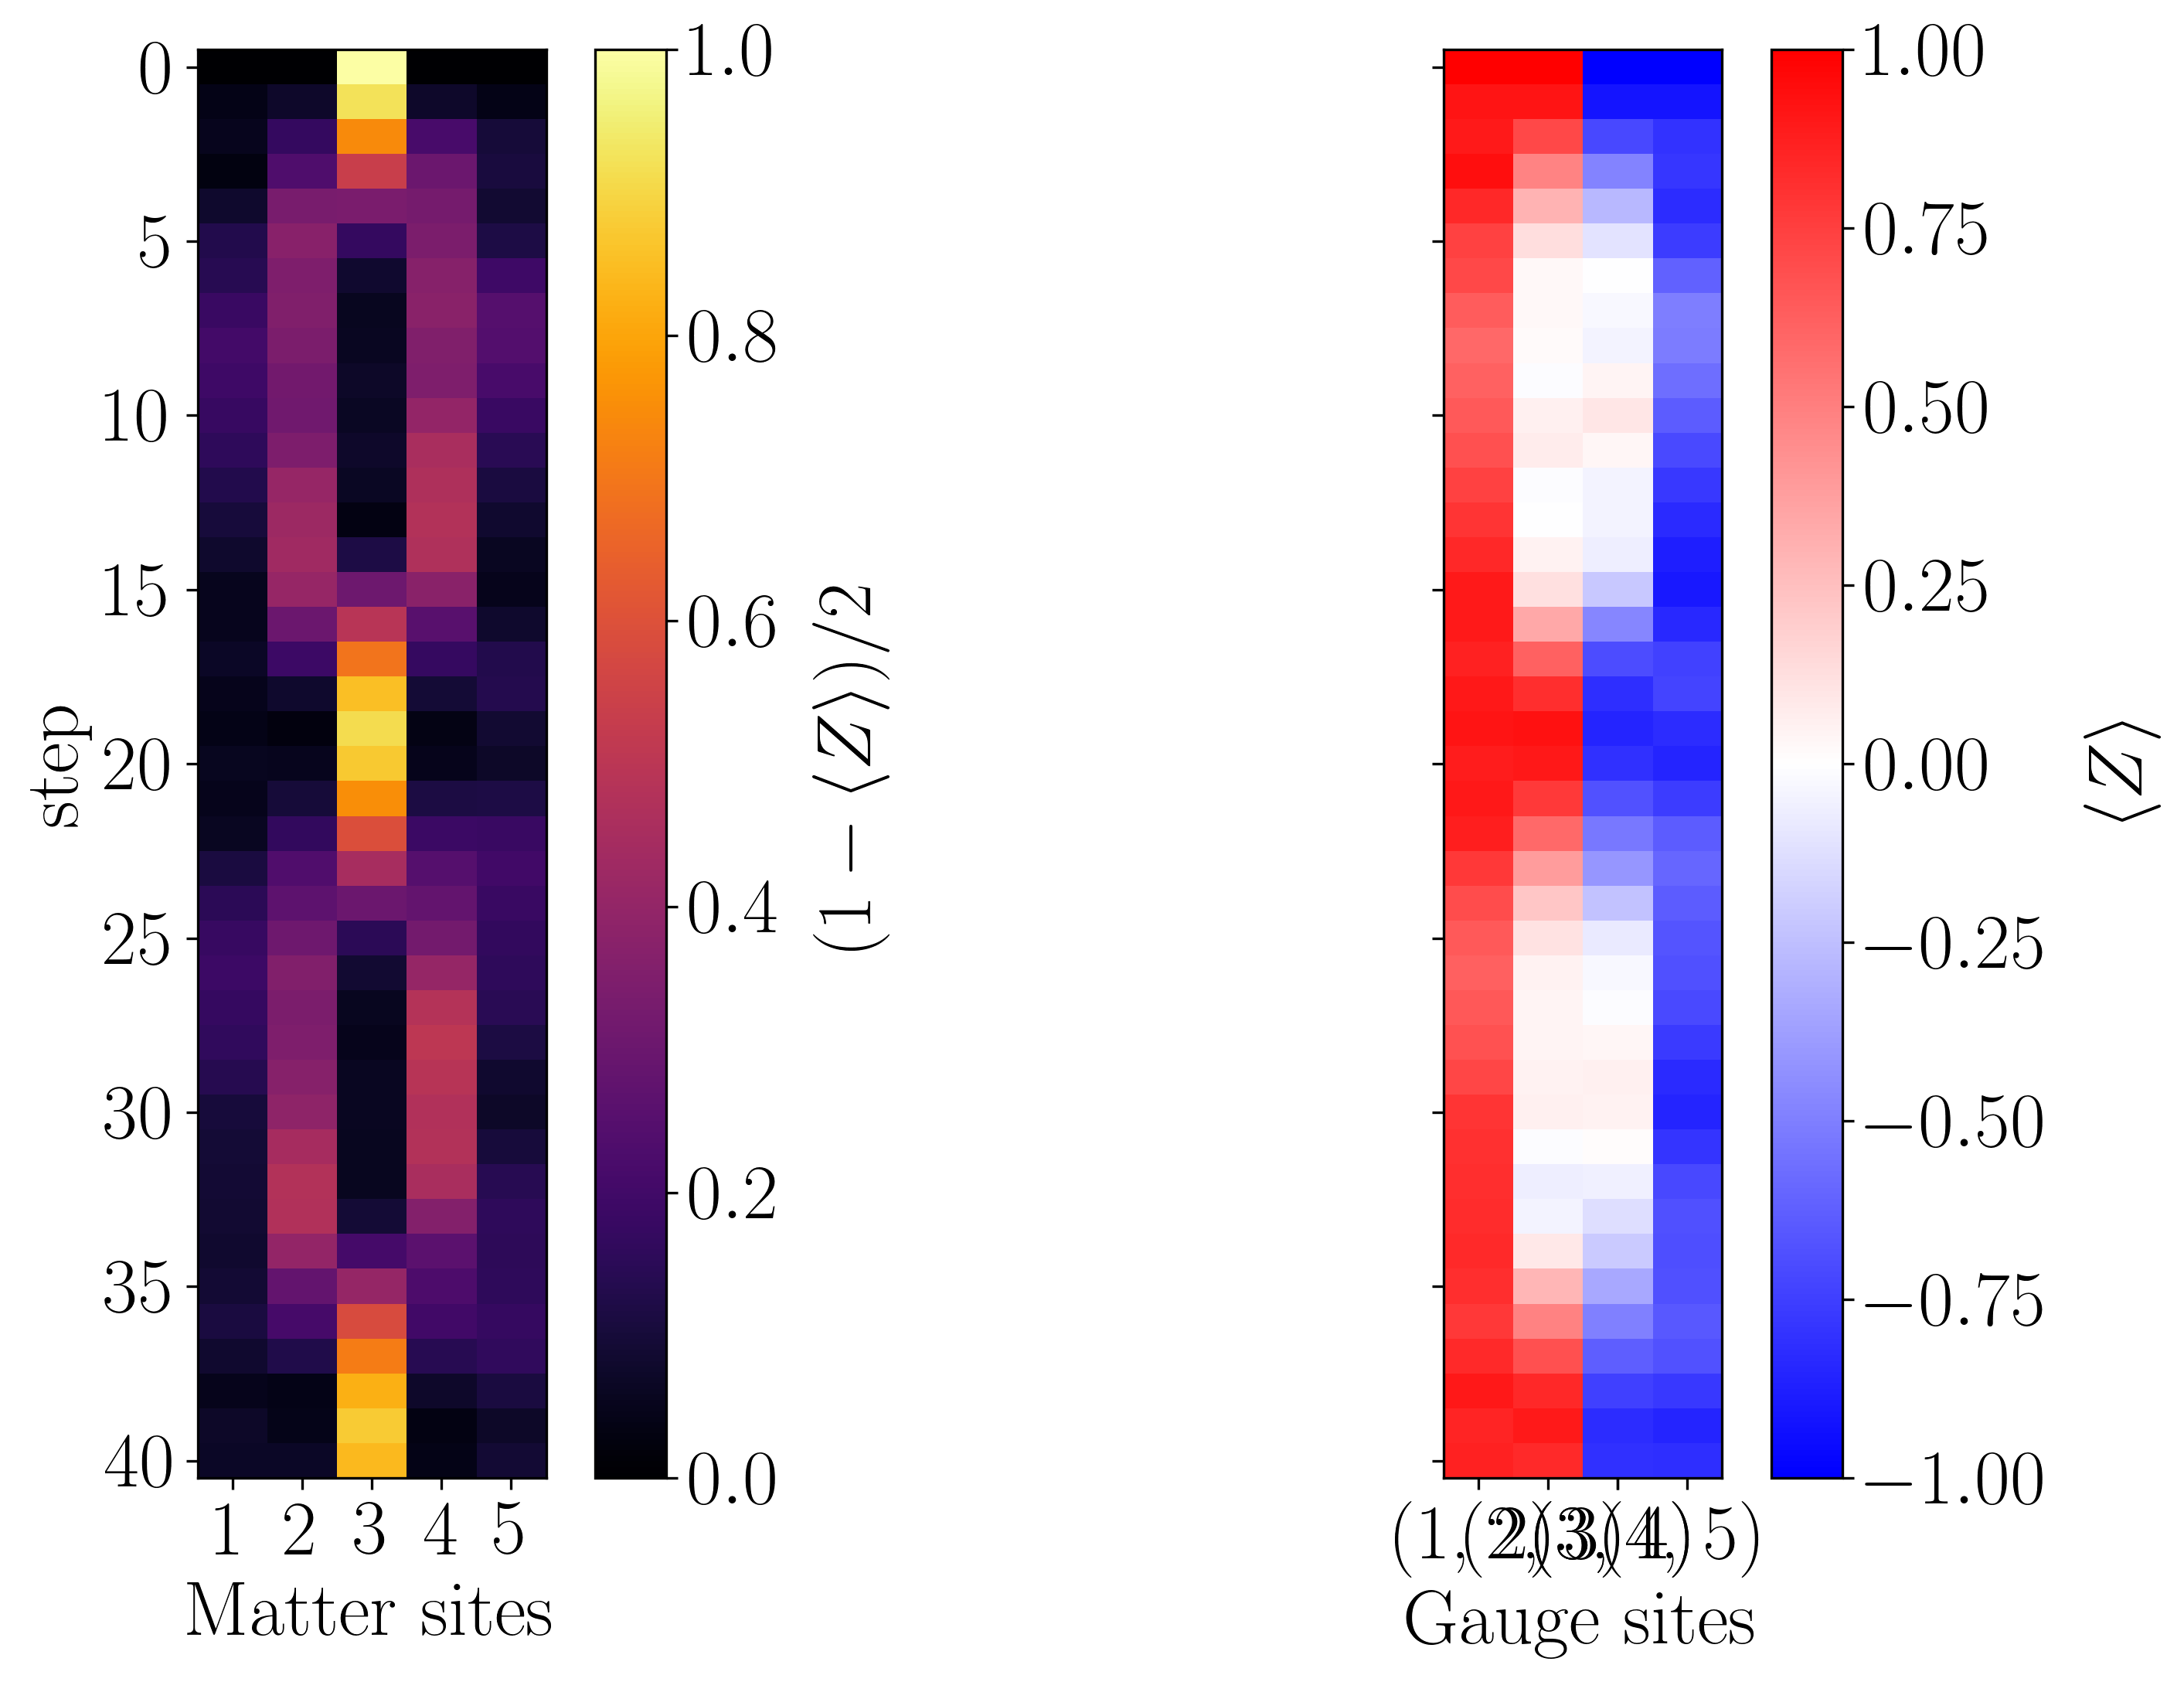

In [8]:
from z2chain.plotting import x_t_separated_plot
import z2chain.exact as exact

exact_observables = exact.singlep_quench_trotter2_simulation(L, J, h, lamb, particle_position, final_time/steps, steps)

x_t_separated_plot(exact_observables)

# Circuit transpilation

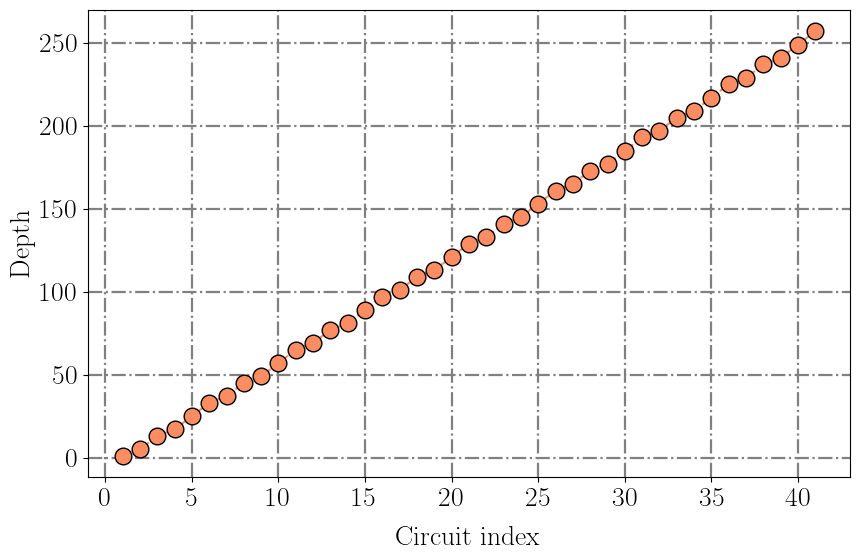

In [9]:
from z2chain.circs import singlep_quench_odr_compuncomp_circuits_dt, singlep_quench_simulation_and_odr_compuncomp_circs
from z2chain.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.hexec import get_backend_best_qubit_chain
from utils.plotting import plot_circuit_arr_depth
import numpy as np
import os

optimization_level = 3
layout = get_backend_best_qubit_chain(backend, 2*L-1)
circs_args = (L, J, h, lamb, particle_position, final_time, dt, steps, backend, optimization_level, g_func, layout, x_basis, False)
if dec:
    circuits, odr_circuits = singlep_quench_simulation_and_odr_compuncomp_circs(*circs_args)
else:
    circuits = singlep_quench_simulation_and_odr_compuncomp_circs(*circs_args)
observable_generating_funcs = [lambda nqubits, i=i: local_pauli_x(nqubits, i) if x_basis else local_pauli_z(nqubits, i) for i in range(2*L-1)]
postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, x_basis)

plot_circuit_arr_depth(circuits)

In [10]:
import numpy as np
import pickle
import os

filepath = os.path.join(results_folder, f"singlep_noisy_sim_{device}_L_{L}_J_{J}_h_{h}_lamb_{lamb}_g_{g_func.__name__ if callable(g_func) else None}_final_time_{final_time}_dt_{dt}_steps_{steps}_shots_{shots}_ppos_{particle_position}_ft_{flip_threshold}_cal_{dec}.pkl")
overwrite = False

if (not os.path.exists(filepath)) or overwrite:
    print("\rRunning simulation...".ljust(100), end="")
    samples_dicts = []
    if dec: dec_samples_dicts = []
    for i in range(len(circuits)):
        print(f"\ri = {i}".ljust(100), end="")
        this_samples_dict = simulator.run(circuits[i], shots=shots).result().get_counts()
        samples_dicts.append(this_samples_dict)
        if dec:
            this_odr_samples_dict = simulator.run(odr_circuits[i], shots=shots).result().get_counts()
            dec_samples_dicts.append(this_odr_samples_dict)
    samples_dicts = np.array(samples_dicts)
    if dec: dec_samples_dicts = np.array(dec_samples_dicts)
    ideal_samples_dicts = [{"0"*(2*L-1):shots}]*len(samples_dicts)
    with open(filepath, "wb") as f:
        pickle.dump((samples_dicts, dec_samples_dicts, ideal_samples_dicts), f)
else:
    with open(filepath, "rb") as f:
        samples_dicts, dec_samples_dicts, ideal_samples_dicts = pickle.load(f)
    print("\rLoaded simulation.".ljust(100), end="")

Loaded simulation.                                                                                 

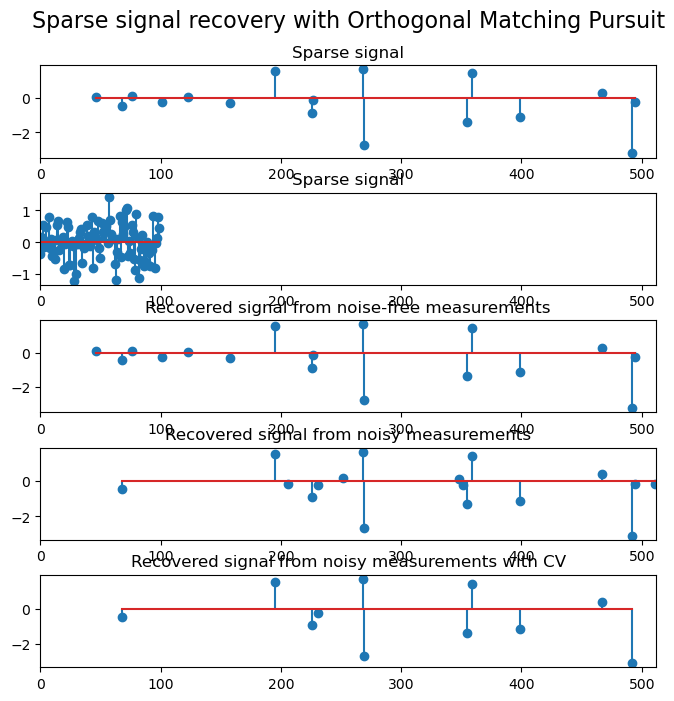

In [ ]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_sparse_coded_signal
from sklearn.linear_model import OrthogonalMatchingPursuit, OrthogonalMatchingPursuitCV

n_components, n_features = 512, 100
n_nonzero_coefs = 17

# generate the data

# y = Xw
# |x|_0 = n_nonzero_coefs

y, X, w = make_sparse_coded_signal(
    n_samples=1,
    n_components=n_components,
    n_features=n_features,
    n_nonzero_coefs=n_nonzero_coefs,
    random_state=0,
)
X = X.T

(idx,) = w.nonzero()

# distort the clean signal
y_noisy = y + 0.05 * np.random.randn(len(y))

# plot the sparse signal
plt.figure(figsize=(7, 7))
plt.subplot(5, 1, 1)
plt.xlim(0, 512)
plt.title("Sparse signal")
plt.stem(idx, w[idx])

# plot the noisy signal
plt.subplot(5, 1, 2)
plt.xlim(0, 512)
plt.title("Sparse signal")
plt.stem(np.arange(len(y_noisy)), y_noisy)

# plot the noise-free reconstruction
omp = OrthogonalMatchingPursuit(n_nonzero_coefs=n_nonzero_coefs)
omp.fit(X, y)
coef = omp.coef_
(idx_r,) = coef.nonzero()
plt.subplot(5, 1, 3)
plt.xlim(0, 512)
plt.title("Recovered signal from noise-free measurements")
plt.stem(idx_r, coef[idx_r])

# plot the noisy reconstruction
omp.fit(X, y_noisy)
coef = omp.coef_
(idx_r,) = coef.nonzero()
plt.subplot(5, 1, 4)
plt.xlim(0, 512)
plt.title("Recovered signal from noisy measurements")
plt.stem(idx_r, coef[idx_r])

# plot the noisy reconstruction with number of non-zeros set by CV
omp_cv = OrthogonalMatchingPursuitCV()
omp_cv.fit(X, y_noisy)
coef = omp_cv.coef_
(idx_r,) = coef.nonzero()
plt.subplot(5, 1, 5)
plt.xlim(0, 512)
plt.title("Recovered signal from noisy measurements with CV")
plt.stem(idx_r, coef[idx_r])

plt.subplots_adjust(0.06, 0.04, 0.94, 0.90, 0.20, 0.38)
plt.suptitle("Sparse signal recovery with Orthogonal Matching Pursuit", fontsize=16)
plt.show()

## ODR (Previous treatment)

In [ ]:
from utils.postselection_multithreaded import initialize_postselection, multiprocess_get_postselected_recovered_samples_dicts, multiprocess_measure_diagonal_observables, compute_depolarizing_probability, pauli_to_str
from qiskit.quantum_info import PauliList, Pauli
from utils.odr import renormalize_observable

odr = True

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(2*L-1, postselection_operators_func, observable_generating_funcs)

postselection_ops_to_str = [pauli_to_str(op) for op in postselection_ops]
to_remove_str = "I"*(2*L-3) + "ZZ"
to_remove_str_ind = postselection_ops_to_str.index(to_remove_str[::-1])
flipped_syndromes = np.zeros(len(postselection_ops_to_str), dtype=int)
flipped_syndromes[to_remove_str_ind] = 1

postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
if odr:
    postselected_odr_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(dec_samples_dicts, postselection_ops, flip_threshold, recovery_function=None)

sim_observables, sim_observables_confidence = multiprocess_measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
raw_observables, raw_observables_confidence = multiprocess_measure_diagonal_observables(samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
if odr:
    odr_observables, odr_observables_confidence = multiprocess_measure_diagonal_observables(postselected_odr_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
    clean_odr_observables = np.zeros_like(sim_observables)
    clean_odr_observables_confidence = np.zeros_like(sim_observables_confidence)
    for i in range(len(sim_observables)):
        p_arr = compute_depolarizing_probability(odr_observables[i], 1, 0, odr_circuits[1].num_qubits)
        clean_odr_observables[i], clean_odr_observables_confidence[i] = renormalize_observable(sim_observables[i], p_arr, 0, circuits[1].num_qubits, observable_range=(-1, 1), expected_observable_arr=1, observable_confidence=sim_observables_confidence[i])

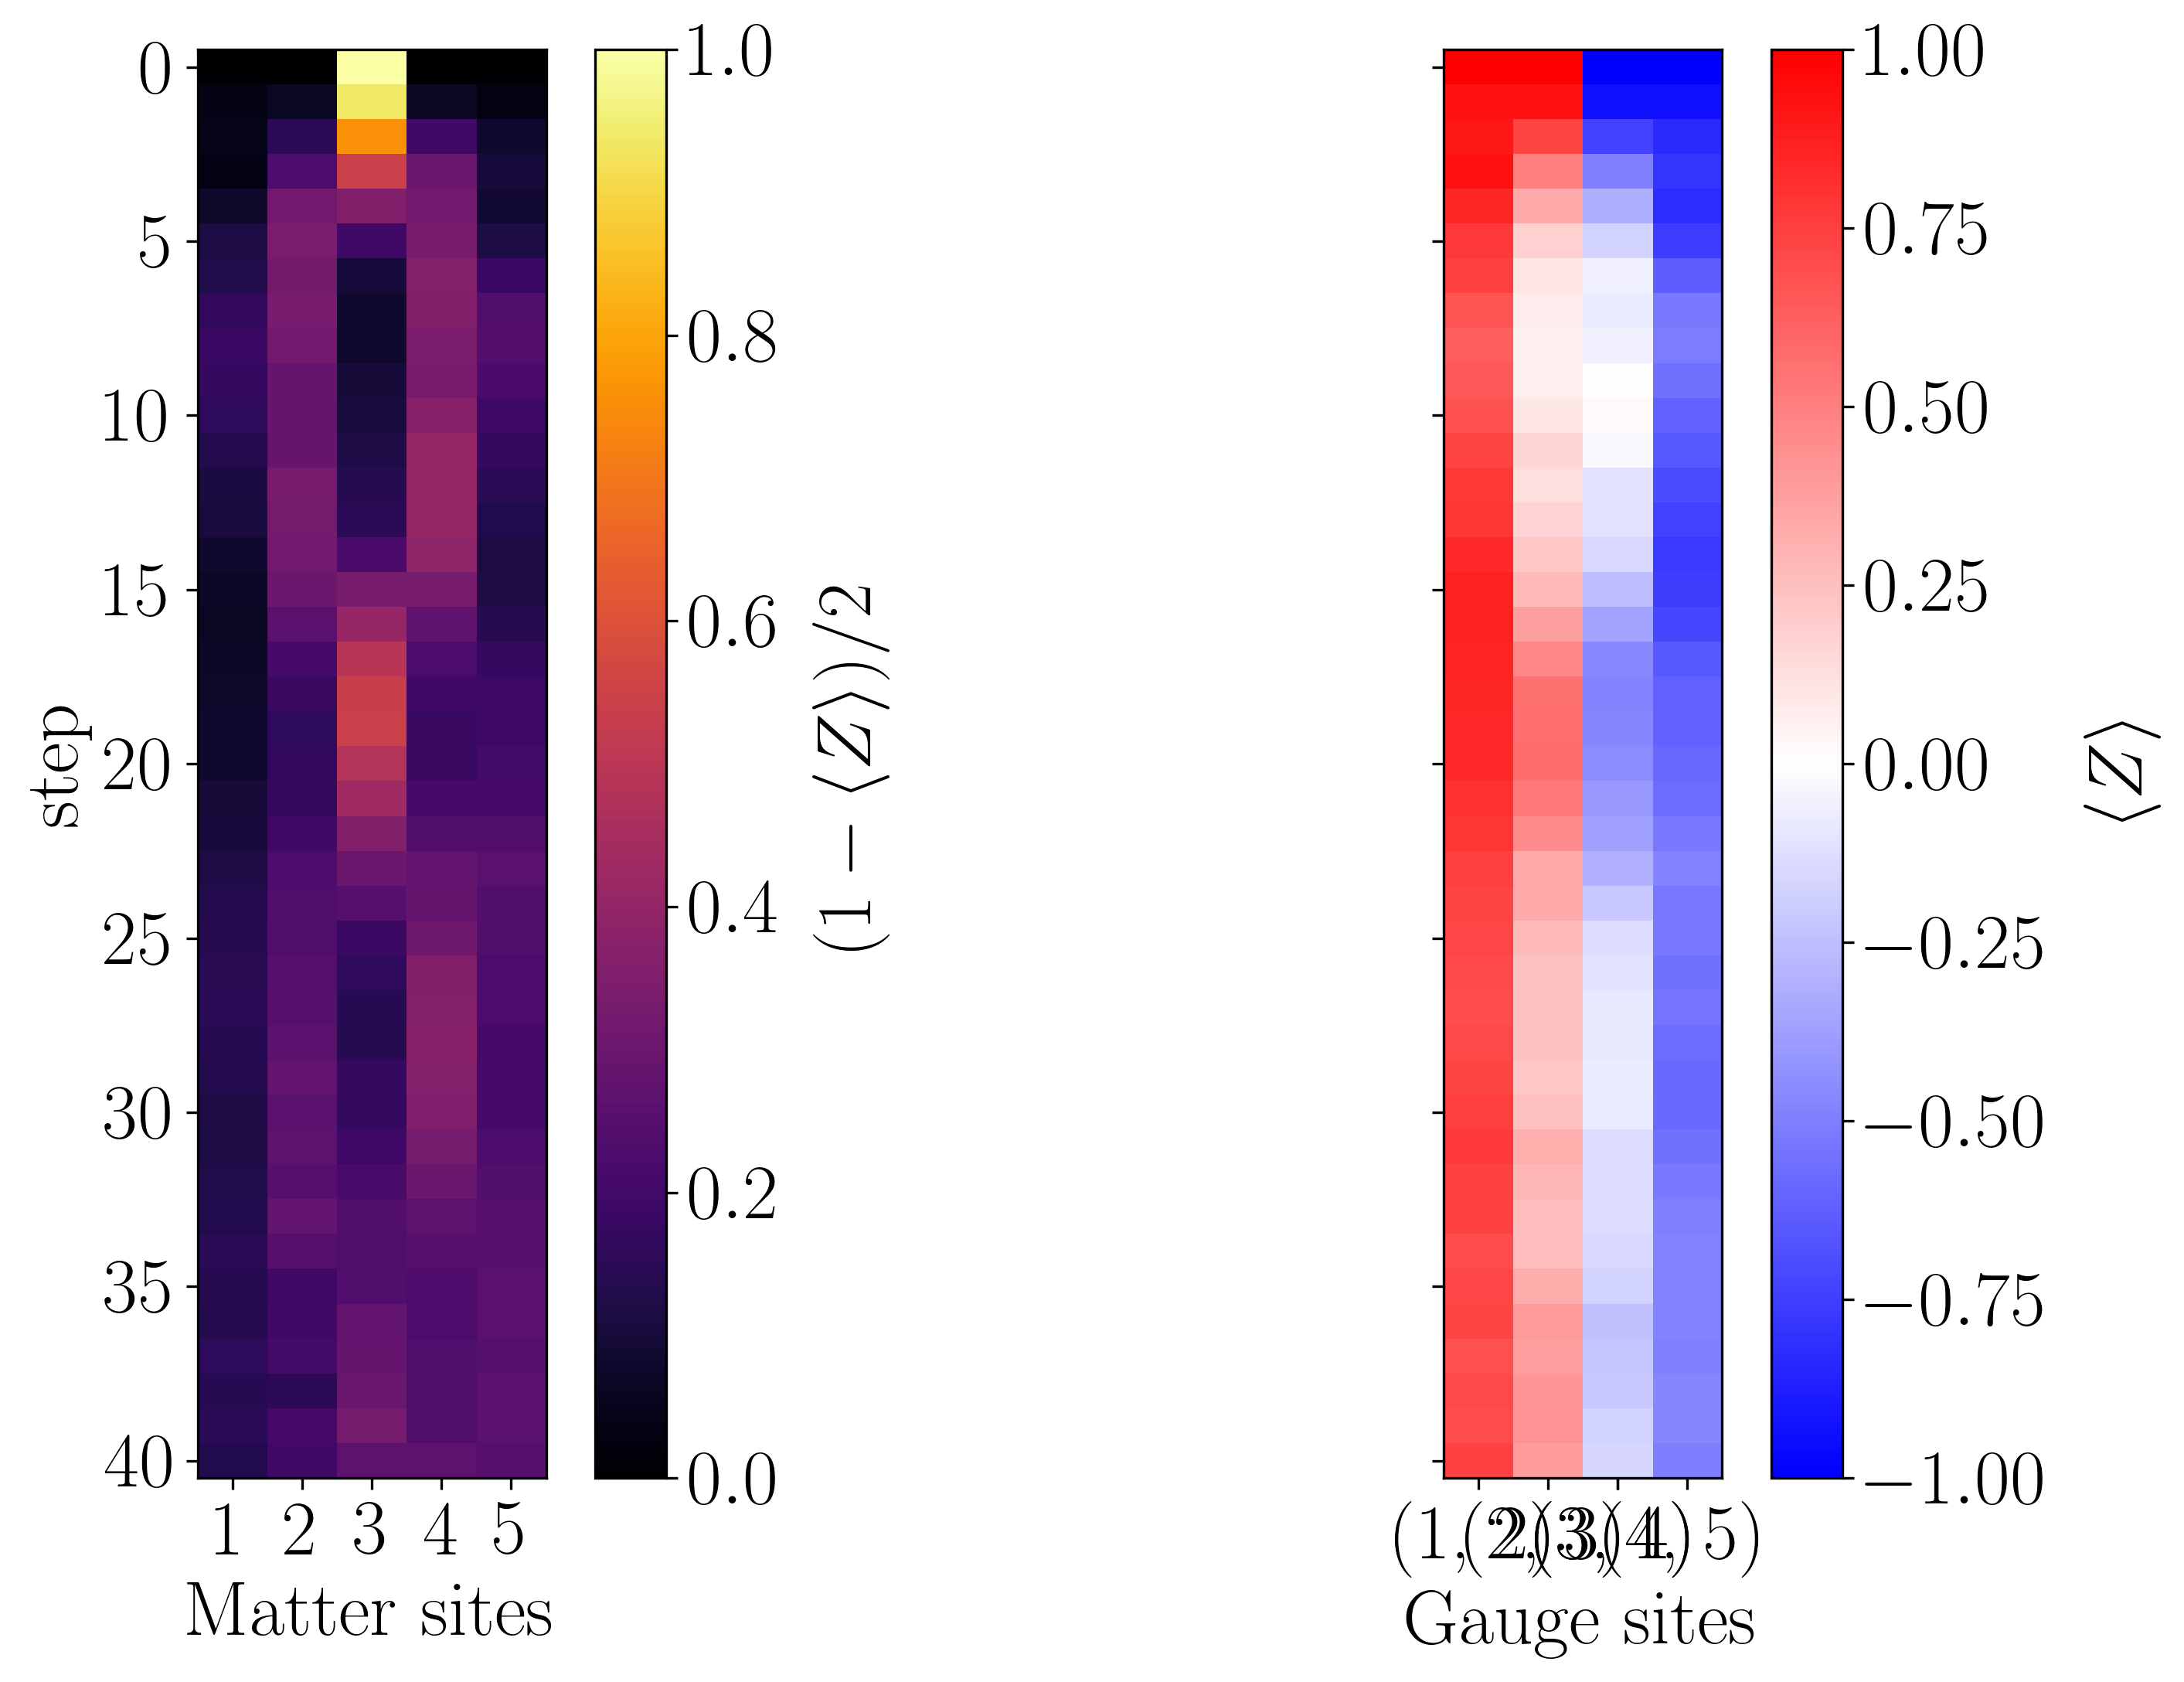

In [ ]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(clean_odr_observables, cbar_range_matter=[0, 1])

## DEC (New approach)

In [ ]:
from utils.postselection_multithreaded import initialize_postselection, multiprocess_get_postselected_recovered_samples_dicts, multiprocess_measure_diagonal_observables, compute_depolarizing_probability, pauli_to_str
from utils.odr import renormalize_observable
import utils.dec as dec
import utils.dec_opt as dec_opt
import numpy as np

trad_corrected_samples_dicts = np.zeros_like(samples_dicts)

for i in range(len(samples_dicts)):
    trad_corrected_samples_dicts[i] = dec_mitigation(samples_dicts[i], dec_samples_dicts[i], ideal_samples_dicts[i])

corrected_samples_dicts = dec_opt.mitigate(samples_dicts, dec_samples_dicts, ideal_samples_dicts)

print("\rMeasuring observables...".ljust(100), end="")
postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(2*L-1, postselection_operators_func, observable_generating_funcs)

postselection_ops_to_str = [pauli_to_str(op) for op in postselection_ops]
to_remove_str = "I"*(2*L-3) + "ZZ"
to_remove_str_ind = postselection_ops_to_str.index(to_remove_str[::-1])
flipped_syndromes = np.zeros(len(postselection_ops_to_str), dtype=int)
flipped_syndromes[to_remove_str_ind] = 1

postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
postselected_samples_dicts.reshape(samples_dicts.shape)
postselected_dec_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(dec_samples_dicts, postselection_ops, flip_threshold, recovery_function=None)
postselected_dec_samples_dicts.reshape(dec_samples_dicts.shape)

# corrected_samples_dicts = np.zeros_like(samples_dicts)

# for i in range(len(samples_dicts)):
#     corrected_samples_dicts[i] = dec_mitigation(samples_dicts[i], dec_samples_dicts[i], ideal_samples_dicts)

# corrected_samples_dicts = dec.multiprocess_mitigate(samples_dicts, dec_samples_dicts, ideal_samples_dicts)

corrected_samples_dicts = dec_opt.mitigate(samples_dicts, dec_samples_dicts, ideal_samples_dicts)

corrected_observables = multiprocess_measure_diagonal_observables(corrected_samples_dicts, diagonal_observables)
corrected_postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(corrected_samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
corrected_postselected_observables, corrected_postselected_observables_confidence = multiprocess_measure_diagonal_observables(corrected_postselected_samples_dicts, diagonal_observables, confidence=confidence, shots=[shots]*len(corrected_postselected_samples_dicts))

trad_corrected_observables = multiprocess_measure_diagonal_observables(corrected_samples_dicts, diagonal_observables)
trad_corrected_postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(trad_corrected_samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
trad_corrected_postselected_observables = multiprocess_measure_diagonal_observables(trad_corrected_postselected_samples_dicts, diagonal_observables)

NameError: name 'samples_dicts' is not defined

In [ ]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(corrected_observables, cbar_range_matter=[0, 1])

NameError: name 'corrected_observables' is not defined

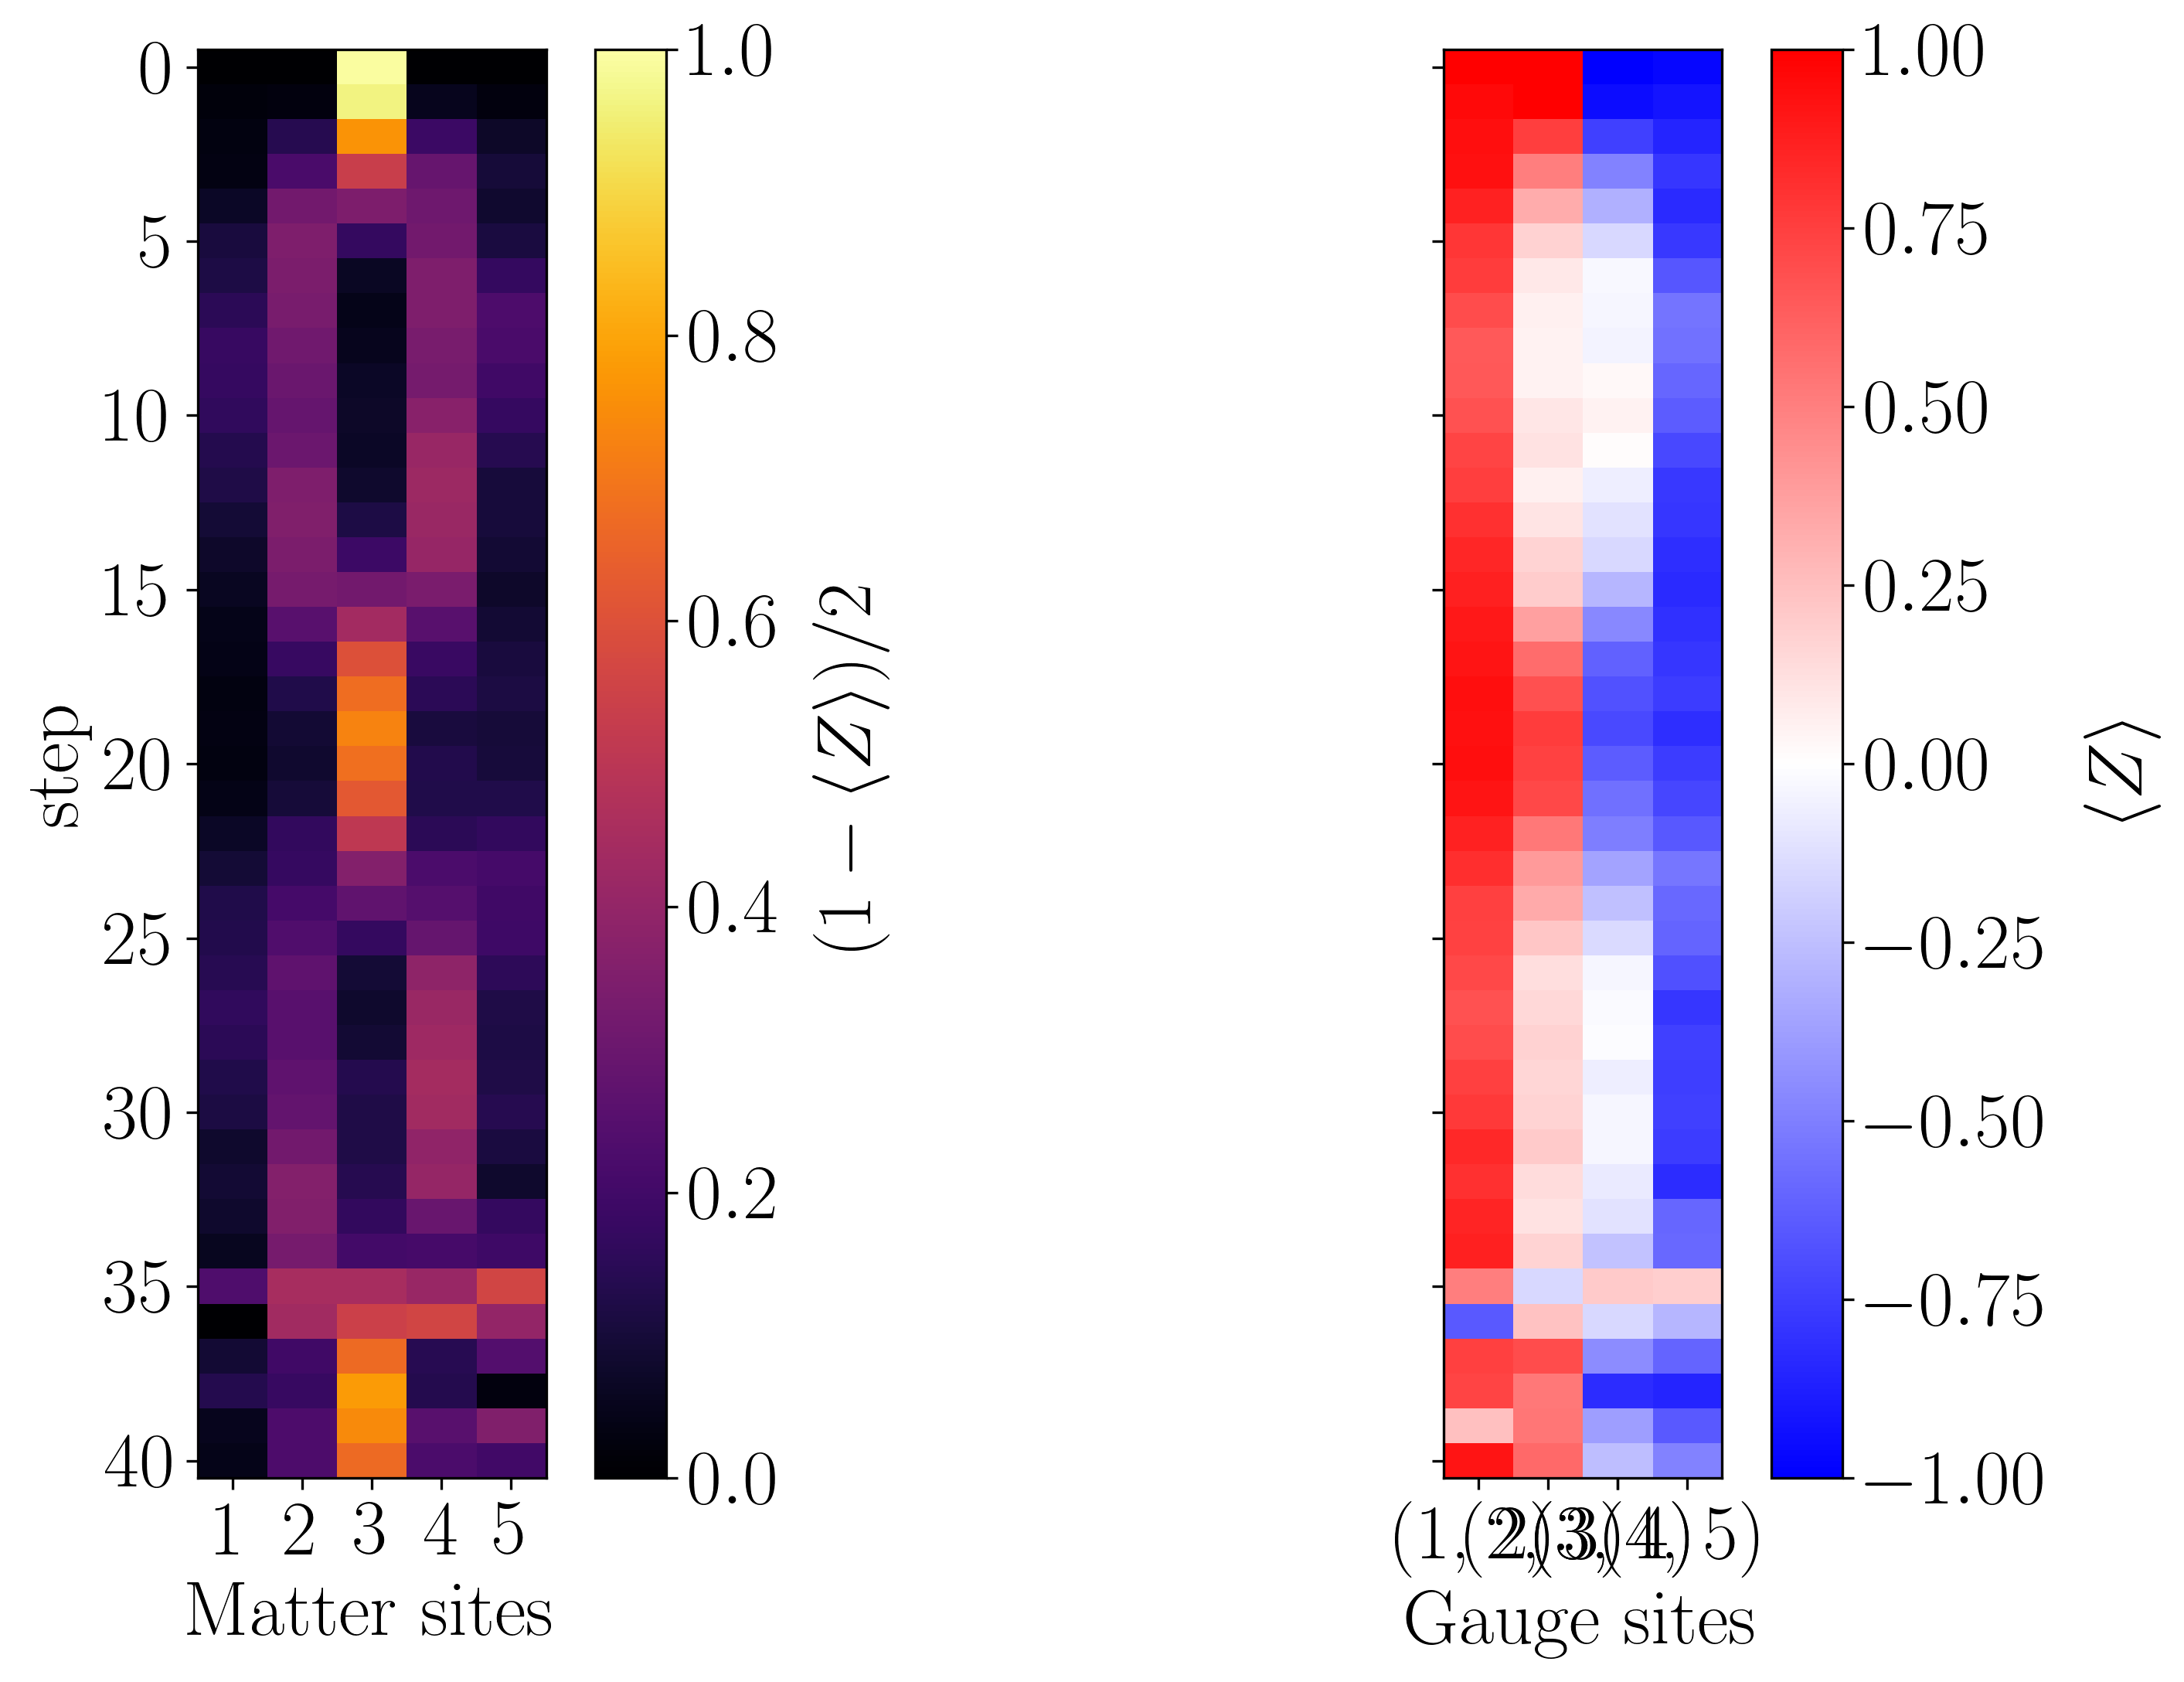

In [ ]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(trad_corrected_observables, cbar_range_matter=[0, 1])

## Comparison among approaches

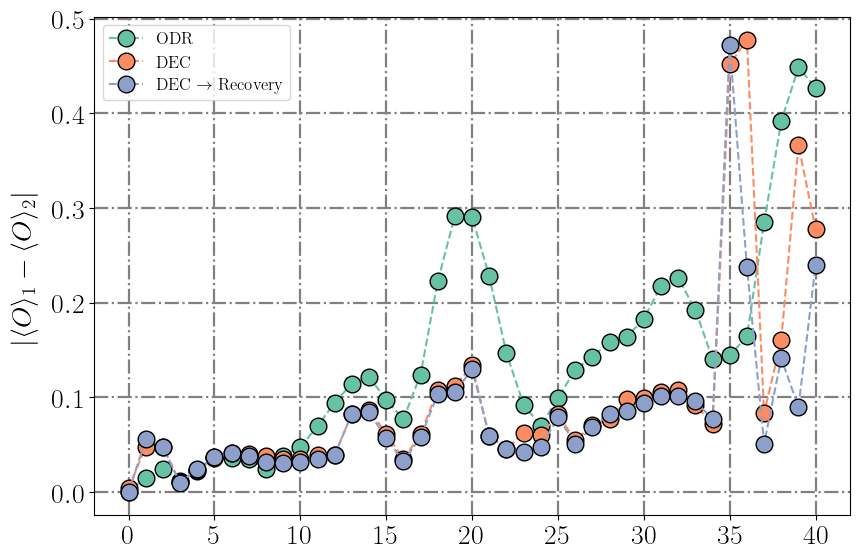

In [ ]:
from utils.plotting import plot_mean_deviations

observables_matrices = [clean_odr_observables, corrected_observables, corrected_postselected_observables]
labels=[r"ODR", r"DEC", r"DEC $\rightarrow$ Recovery"]

plot_mean_deviations(observables_matrices, [exact_observables]*len(observables_matrices), labels=labels)

# Playground

In [ ]:
from qiskit.result import QuasiDistribution
import utils.dec_opt as dec_opt

job_index = 0
nqubits = 2*L-1
num_keep = 2**20

payload_noisy_samples = samples_dicts[job_index]
calibration_noisy_samples = dec_samples_dicts[job_index]
calibration_ideal_samples = ideal_samples_dicts[job_index]

def count_nonzero(vec):
    return len(vec[~np.isclose(vec, 0)])

# ----- Current fill_upto ----- #
# Compute the max length of the samples dicts
max_basis_dim = 0
for psamples, csamples in zip(payload_noisy_samples, calibration_noisy_samples):
    this_max_nbasis = max(len(psamples), len(csamples))
    if this_max_nbasis > max_basis_dim:
        max_basis_dim = this_max_nbasis
max_basis_dim = 2**(int(np.ceil(np.log2(max_basis_dim))) + 1)

# Generate the distribution vectors with correct ordering and length
psamples = convert_to_first_col(payload_noisy_samples, list(ideal_samples_dicts[0].keys())[0])
psamples = filter_counts(psamples, num_keep)
csamples = filter_counts(calibration_noisy_samples, num_keep)
pvec, cvec, int_labels = dec_opt.samples_to_vecs(psamples, csamples, None)
fill_upto_current = len(pvec)
print("Fill upto current: ", fill_upto_current)

# Get corrected distribution
quasi_corrected_pvec_current = dec_opt.get_quasi_corrected(cvec, pvec)
corrected_quasi_dist_dict = {bin(label)[2:].zfill(nqubits):prob for label, prob in zip(int_labels, quasi_corrected_pvec_current)}
corrected_quasi_dist_current = QuasiDistribution(corrected_quasi_dist_dict).nearest_probability_distribution().binary_probabilities(nqubits)

# ----- Exponential fill_upto ----- #
# Compute the max length of the samples dicts
max_basis_dim = 0
for psamples, csamples in zip(payload_noisy_samples, calibration_noisy_samples):
    this_max_nbasis = max(len(psamples), len(csamples))
    if this_max_nbasis > max_basis_dim:
        max_basis_dim = this_max_nbasis
max_basis_dim = 2**(int(np.ceil(np.log2(max_basis_dim))) + 1)

# Generate the distribution vectors with correct ordering and length
psamples = convert_to_first_col(payload_noisy_samples, list(ideal_samples_dicts[0].keys())[0])
psamples = filter_counts(psamples, num_keep)
csamples = filter_counts(calibration_noisy_samples, num_keep)
pvec, cvec, int_labels = dec_opt.samples_to_vecs(psamples, csamples, 2**nqubits)
fill_upto_exponential = len(pvec)
print("Fill upto exponential: ", fill_upto_exponential)

# Get corrected distribution
quasi_corrected_pvec_exponential = dec_opt.get_quasi_corrected(cvec, pvec)
corrected_quasi_dist_dict = {bin(label)[2:].zfill(nqubits):prob for label, prob in zip(int_labels, quasi_corrected_pvec_exponential)}
corrected_quasi_dist_exponential = QuasiDistribution(corrected_quasi_dist_dict).nearest_probability_distribution().binary_probabilities(nqubits)

Fill upto current:  128
Fill upto exponential:  512


In [1]:
import utils.dec_opt as dec_opt
import numpy as np

pvec = np.random.rand(2**25)

%timeit dec_opt.hadamard_transform(pvec)

2.13 s ± 38.4 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [ ]:
np.sort(quasi_corrected_pvec_current)[::-1]

array([ 1.00054492e+00,  3.03812512e-02,  2.41698896e-02,  1.45208063e-02,
        1.34183847e-02,  5.94006827e-03,  5.57487409e-03,  5.13910231e-03,
        4.36583913e-03,  1.54604677e-03,  8.10516500e-04,  8.09454590e-04,
        6.76101291e-04,  6.37823571e-04,  4.67083003e-04,  4.52892563e-04,
        3.68900650e-04,  3.48739416e-04,  3.19020813e-04,  3.12393137e-04,
        2.75969503e-04,  2.25019268e-04,  2.20544624e-04,  2.05054194e-04,
        2.04877192e-04,  1.97796047e-04,  1.79110930e-04,  1.47148082e-04,
        1.29788145e-04,  1.15683921e-04,  9.14286946e-05,  8.02190921e-05,
        7.36117230e-05,  7.23254537e-05,  6.14192782e-05,  5.40133811e-05,
        5.24899464e-05,  4.36360041e-05,  3.38175631e-05,  3.32792932e-05,
        3.25611509e-05,  3.04081084e-05,  2.92018960e-05,  2.77497726e-05,
        2.68132332e-05,  2.59999236e-05,  2.32016571e-05,  2.11545888e-05,
        1.71664997e-05,  1.70251885e-05,  1.69881435e-05,  1.57032891e-05,
        1.54718415e-05,  

In [ ]:
np.sort(np.abs(quasi_corrected_pvec_exponential))[::-1]

array([9.98510593e-01, 1.43396533e-03, 9.09323893e-04, 7.37860048e-04,
       6.21056310e-04, 5.58463870e-04, 5.29303568e-04, 3.38912974e-04,
       3.32209957e-04, 3.18664323e-04, 1.76366907e-04, 1.67352388e-04,
       1.48112284e-04, 9.83391636e-05, 8.93154771e-05, 6.35320878e-05,
       6.22202480e-05, 5.80419364e-05, 5.32202862e-05, 5.00260675e-05,
       4.59413773e-05, 4.53477675e-05, 4.45628331e-05, 4.39403865e-05,
       4.37413307e-05, 3.93741285e-05, 3.93523813e-05, 3.72642704e-05,
       3.39163918e-05, 3.31077622e-05, 3.25541784e-05, 2.90061453e-05,
       2.70638588e-05, 2.43891783e-05, 2.28183074e-05, 2.26193435e-05,
       2.19994515e-05, 2.13807920e-05, 2.00426638e-05, 1.88257467e-05,
       1.54899258e-05, 1.54540583e-05, 1.53585744e-05, 1.53542696e-05,
       1.50646528e-05, 1.50100600e-05, 1.49729422e-05, 1.48088401e-05,
       1.46234003e-05, 1.44253381e-05, 1.43919575e-05, 1.43125955e-05,
       1.41893088e-05, 1.41635169e-05, 1.41372630e-05, 1.08752766e-05,
      

In [ ]:
corrected_quasi_dist_current

{'010100000': 0.005804534894738117,
 '000110000': 0.01201589654710582,
 '010110000': 0.9821795685581561}

In [ ]:
corrected_quasi_dist_exponential

{'010110001': 1.278009843364578e-06,
 '010110010': 0.00019837162078147302,
 '010010000': 0.0002275319223603541,
 '010110100': 0.00029012436231232153,
 '011110000': 0.0011030333855449428,
 '010110000': 0.9981796606991575}

## They are indeed different 🤔

In [18]:
import utils.dec as dec
import utils.dec_opt as dec_opt

job_index = 0

csamplesopt = dec_opt.mitigate(samples_dicts[0], dec_samples_dicts[0], ideal_samples_dicts[0])

# Julia

In [1]:
from juliacall import Main as jl, convert as jlconvert
import juliacall
from juliacall import DictValue

a = {"0": 10, "11":20}

jl.Dict[jl.String, jl.Int](a)

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


Dict{String, Int64} with 2 entries:
  "0"  => 10
  "11" => 20

# Fixing confidence intervals for this method

In [ ]:
job_index = 10

samples_dict = samples_dicts[job_index]
postselected_samples_dict = postselected_samples_dicts[job_index]
corrected_samples_dict = corrected_samples_dicts[job_index]

In [ ]:
corrected_samples_dict

{'010110001': 3.0054696830766555e-05,
 '010010000': 0.0009890831176697936,
 '010110111': 0.0012505818439726539,
 '100101100': 0.0013107833282007598,
 '101101011': 0.0014456076785356368,
 '010110011': 0.001686141087134692,
 '101101000': 0.002891985812815874,
 '101100000': 0.003133147406404245,
 '010110100': 0.0033084411648435846,
 '101110000': 0.0035757227288150694,
 '010111000': 0.0038750293282609582,
 '101101100': 0.003906310669505508,
 '011011100': 0.003928403387269264,
 '000011100': 0.004732541738529796,
 '100011100': 0.00512917152654114,
 '011011000': 0.005726280764889644,
 '110110000': 0.0059158181348890745,
 '011011011': 0.01201002093468221,
 '010100000': 0.014288683451793096,
 '010000000': 0.016996543349118983,
 '010110000': 0.02821817362971428,
 '010101011': 0.1494333178981435,
 '100000000': 0.15181640990707304,
 '010101100': 0.24176302705093758,
 '011000000': 0.3326387193634288}

In [ ]:
from utils.postselection_multithreaded import measure_diagonal_observables_with_basis, generate_observables

diagonal_observables, non_diagonal_observables = generate_observables(2*L-1, observable_generating_funcs)

measure_diagonal_observables_with_basis(corrected_samples_dict, diagonal_observables, "Z", 0.7, shots)

(array([ 0.66828855,  0.66834866,  0.46934148,  0.12769504,  0.83924907,
         0.06793435,  0.2614876 , -0.64411664,  0.64175009]),
 array([[ 0.63347727,  0.71150922],
        [ 0.62751145,  0.70686275],
        [ 0.42831176,  0.52146392],
        [ 0.06962031,  0.18226068],
        [ 0.81133364,  0.87155463],
        [ 0.02067702,  0.12822122],
        [ 0.21206018,  0.30957347],
        [-0.68474898, -0.60309749],
        [ 0.60125494,  0.68275431]]))

In [ ]:
observable_generating_funcs

[<function __main__.<lambda>(nqubits, i=0)>,
 <function __main__.<lambda>(nqubits, i=1)>,
 <function __main__.<lambda>(nqubits, i=2)>,
 <function __main__.<lambda>(nqubits, i=3)>,
 <function __main__.<lambda>(nqubits, i=4)>,
 <function __main__.<lambda>(nqubits, i=5)>,
 <function __main__.<lambda>(nqubits, i=6)>,
 <function __main__.<lambda>(nqubits, i=7)>,
 <function __main__.<lambda>(nqubits, i=8)>]

In [ ]:
tests_dict = {f"{i:020b}":np.random.randint(0, 100) for i in range(2**20)}

In [ ]:
import utils.dec as dec

dec.convert_to_first_col(tests_dict, "0"*20)

{'00000000000000000000': 10,
 '00000000000000000001': 54,
 '00000000000000000010': 94,
 '00000000000000000011': 9,
 '00000000000000000100': 40,
 '00000000000000000101': 45,
 '00000000000000000110': 32,
 '00000000000000000111': 62,
 '00000000000000001000': 2,
 '00000000000000001001': 42,
 '00000000000000001010': 97,
 '00000000000000001011': 67,
 '00000000000000001100': 60,
 '00000000000000001101': 30,
 '00000000000000001110': 44,
 '00000000000000001111': 15,
 '00000000000000010000': 30,
 '00000000000000010001': 79,
 '00000000000000010010': 64,
 '00000000000000010011': 39,
 '00000000000000010100': 81,
 '00000000000000010101': 66,
 '00000000000000010110': 18,
 '00000000000000010111': 37,
 '00000000000000011000': 60,
 '00000000000000011001': 19,
 '00000000000000011010': 95,
 '00000000000000011011': 2,
 '00000000000000011100': 15,
 '00000000000000011101': 95,
 '00000000000000011110': 22,
 '00000000000000011111': 16,
 '00000000000000100000': 7,
 '00000000000000100001': 55,
 '0000000000000010

In [ ]:
dec.filter_counts(tests_dict, 2**18)

{'00000000000001000101': 99,
 '00000000000010010010': 99,
 '00000000000100111001': 99,
 '00000000001100000010': 99,
 '00000000001100010110': 99,
 '00000000001101011011': 99,
 '00000000001101011110': 99,
 '00000000001101100010': 99,
 '00000000001101100111': 99,
 '00000000001101110011': 99,
 '00000000001110010100': 99,
 '00000000010000011111': 99,
 '00000000010001000000': 99,
 '00000000010010001010': 99,
 '00000000010010100111': 99,
 '00000000010101011001': 99,
 '00000000010110000100': 99,
 '00000000011000010010': 99,
 '00000000011001110100': 99,
 '00000000011010000100': 99,
 '00000000011010111100': 99,
 '00000000011010111101': 99,
 '00000000100001000011': 99,
 '00000000100010110110': 99,
 '00000000100010111110': 99,
 '00000000100011100000': 99,
 '00000000100100000010': 99,
 '00000000100100011000': 99,
 '00000000100101110101': 99,
 '00000000100110010000': 99,
 '00000000100110110101': 99,
 '00000000101000101111': 99,
 '00000000101001101100': 99,
 '00000000101010010001': 99,
 '000000001010

In [ ]:
import numpy as np

num_keep = 25
a = np.array([9, 10, 12, 15]) # Sorted array

if num_keep > a[-1]:
    final = np.arange(num_keep)
else:
    ints_until_elp1 = np.concatenate(([a[0]], np.cumsum(np.diff(a)) + a[0] + 1))
    between_limit = np.argwhere(np.greater(ints_until_elp1, num_keep))[0][0]
    nremaining = num_keep - len(a[between_limit::])
    to_fill = np.arange(nremaining)
    final = np.concatenate((to_fill, a[between_limit:]))

final

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24])